## Pytorch_Alpha

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import time
import pickle
import torch
import torch.nn as nn
import torch.optim as optim
import random
from torch.utils.data import * 
import datetime

In [2]:
if (torch.cuda.is_available()):
    device=torch.device("cuda")
    print('device is:',device)
else:
    device=torch.device("cpu")
    print('device is:',device)

device is: cpu


In [ ]:
torch.__version__

## Load Training Data

In [3]:
alpha_pixels = np.load("../Pixel_data/alpha_pixels_BiomeA.npy")                   # All Africa
alpha_pixels.shape

(20834, 64)

## Load Labels

In [4]:
alpha_labels = np.load("../Pixel_data/alpha_pixels_BiomeA_labels.npy")    
alpha_labels.shape

(20834,)

In [6]:
alpha_label_names = ['Water(0)','Developed(1)','Barren(2)','Trees(3)','Shrub(4)','Grassland(5)','Agriculture(6)']
len(alpha_label_names)

7

In [8]:
alpha_labels.min(),alpha_labels.max()

(0, 6)

## Convert from Digital Number to Surface Reflectance

In [9]:
alpha_pixels.min(),alpha_pixels.max(),alpha_pixels.mean()

(-0.4982698961937717, 0.48725874663590923, -0.009768986077566627)

## Create a Dataset Subclass - from Dataset Class

IDL page 26. Using common notation in ML, we need a set of input data X and associated output labels y. In PyTorch we represent that with a
`Dataset` object. By using this interface, PyTorch provides efficient loaders that automatically handle using multiple CPU cores to
pre-fetch the data and keep a limited amount of data in memory at a time.  
From `torch.utils.data import Dataset`  


In [10]:
class Pixel_Dataset(Dataset):                # create a subclass of the Dataset class
        
    def __init__(self, X, y):                # X = input data, y is corresponding labels
        super().__init__()                   # Call the parent class's __init__ (not needed for Dataset but best practice)
        self.X = X
        self.y = y
         
    def __getitem__(self, index):            # get specific sample data and corresponding label & convert to tensor
        return torch.tensor(self.X[index], dtype=torch.float32), torch.tensor(self.y[index], dtype=torch.long)

    def __len__(self):
        return self.X.shape[0]


## Create a Dataset Object and Split into Training and Test Dataset

In [11]:
# Alpha pixel data
pixel_ds = Pixel_Dataset(alpha_pixels, alpha_labels)               # create Image_Dataset object - normalised
train_size = int(len(pixel_ds)*0.8)                                # training size is 80%
test_size = len(pixel_ds) - train_size                             # test size is 20%
training_dataset, test_dataset = random_split(pixel_ds, (train_size, test_size))  # split the dataset into two; training and test
len(training_dataset), len(test_dataset), len(training_dataset) + len(test_dataset)

(16667, 4167, 20834)

## Define Model Class from nn.Module Class

In [12]:
# two fully connected layers and a softmax - 64 input features
class Alpha_FC(nn.Module):
    def __init__(self):                                               # instantiate in the constructor
        super().__init__()                                            # in - m x 10
        self.fc1 = nn.Linear(64, 32)                                  # fc1. out - m x 10
        self.act1 = nn.LeakyReLU()                                    # activation 1
        self.fc2 = nn.Linear(32, 16)                                  # fc2. out - m x 10
        self.act2 = nn.LeakyReLU()                                    # activation 2
        self.fc3 = nn.Linear(16,7)                                    # out - m x 6 - 7 classes

    def forward(self, x):                             
        out = self.act1(self.fc1(x))
        out = self.act2(self.fc2(out))
        out = self.fc3(out)       
        return out

## Instantiate the Model Object

In [13]:
# instantiate new model
model = Alpha_FC()    # Constructor - Patch is the class (subclass of nn.Module), model is the object

numel_list= [ p.numel() for p in model.parameters()]
sum(numel_list),numel_list

(2727, [2048, 32, 512, 16, 112, 7])

In [14]:
print(model)

Alpha_FC(
  (fc1): Linear(in_features=64, out_features=32, bias=True)
  (act1): LeakyReLU(negative_slope=0.01)
  (fc2): Linear(in_features=32, out_features=16, bias=True)
  (act2): LeakyReLU(negative_slope=0.01)
  (fc3): Linear(in_features=16, out_features=7, bias=True)
)


## Train the Model

In [15]:
# Training Loader - from training dataset and batch size
training_loader = DataLoader(training_dataset, batch_size=10, shuffle=True, drop_last=True)

In [16]:
print('total samples =', len(training_dataset))
print('no of batches =', len(training_loader))

total samples = 16667
no of batches = 1666


In [19]:
# Training Model
print(datetime.datetime.now())

start = time.time()

epochs = 5
model = model.to(device)
optimizer = optim.SGD(model.parameters(), lr=0.01)                         # standard SGD. optimizer after moving model to device
loss_fn = nn.CrossEntropyLoss()                                            # Softmax + Negative Log Likelihood
                                                                           # model output shape is Batch x Classes
model.train()             # Put our model in training mode
    
average_loss=[]

no_batches = len(training_loader)
    
for epoch in range(1,epochs+1):

    running_loss = 0.0

    for pixels, labels in training_loader:

        pixels = pixels.to(device)
        labels = labels.to(device)

        outputs = model(pixels)              # run model. inputs [batch_size,features] outputs [batch_size,num_classes]
        loss = loss_fn(outputs, labels)      # calculate loss. labels [batch_size]. mean loss over all batch samples
                                             # NLLLoss delivers one loss per sample. The negative log likelihood
                                             # ...where likelihood is probability of the target class
        optimizer.zero_grad()                # set grads to zero
        loss.backward()                      # calculate gradients
        optimizer.step()                     # update paramers
            
        running_loss += loss.item()          # item() returns the value of this tensor as a standard Python number... 
                                             # this only works for tensors with one element.
            
    average_loss.append(running_loss/no_batches)
    if (epoch % 1 == 0):
        print("Epoch: %d, Average Loss: %f" % (epoch, running_loss/no_batches))
                
end = time.time()
print('\n\nfinal run time=',(end-start)/60," minutes")

2026-03-09 12:24:41.274163
Epoch: 1, Average Loss: 1.095030
Epoch: 2, Average Loss: 0.573196
Epoch: 3, Average Loss: 0.441451
Epoch: 4, Average Loss: 0.386572
Epoch: 5, Average Loss: 0.353940


final run time= 0.44763656457265216  minutes


In [ ]:
# which device is model on, cpu or gpu
print('model device=',next(model.parameters()).device)
print('outputs device=',outputs.device)

## Plot Loss

In [20]:
########################## change this #########################
model_name='Alpha_BiomeA'

In [21]:
figure_name='../Pixel_models/plot_loss_' + model_name + '.jpg'
figure_name

'../Pixel_models/plot_loss_Alpha_BiomeA.jpg'

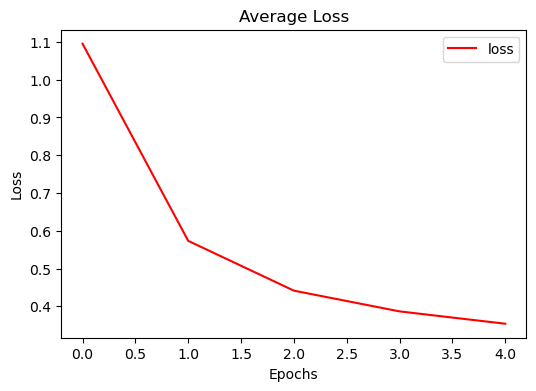

In [23]:
# plot average loss curve

plt.figure(figsize=(6, 4))  # width, height

plt.plot(average_loss,'red',label='loss') 

# Add titles and labels
plt.title('Average Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')   
plt.legend()

plt.savefig(figure_name, dpi=600, bbox_inches="tight")

plt.show()

In [24]:
file_name='../Pixel_models/aloss_' + model_name + '.npy'
file_name

'../Pixel_models/aloss_Alpha_BiomeA.npy'

In [25]:
# save loss data as np array
np.save(file_name, np.array(average_loss))

In [28]:
# load loss data 
rloss_load = np.load("../Pixel_models/aloss_Alpha_BiomeA.npy")    
len(rloss_load)

5

## Test the Model

In [29]:
test_loader = DataLoader(test_dataset, batch_size=len(test_dataset), shuffle=False)   # a single batch

In [30]:
len(test_loader), test_loader.batch_size

(1, 4167)

In [31]:
model.eval()

with torch.no_grad():
    for pixels, labels in test_loader:
        pixels = pixels.to(device)
        labels = labels.to(device)
        
        outputs = model(pixels)
        predicted_index = torch.argmax(outputs, dim=1)
        total = pixels.shape[0]
        correct = int((predicted_index == labels).sum())
        
print("Accuracy: %f" % (correct * 100 / total))
print("correct =",correct)
print("total =", total)

Accuracy: 90.136789
correct = 3756
total = 4167


In [32]:
predicted_index.shape, labels.shape

(torch.Size([4167]), torch.Size([4167]))

## Confusion Matrix and F1 Score

In [33]:
figure_name='../Pixel_models/plot_confusion_' + model_name + '.jpg'
figure_name

'../Pixel_models/plot_confusion_Alpha_BiomeA.jpg'

In [34]:
import seaborn as sns
from sklearn.metrics import confusion_matrix, f1_score

# Example data
y_true = labels
y_pred = predicted_index

f1_macro = f1_score(y_true, y_pred, average='macro') # Averages F1 across all classes equally, no matter how big or small they are
f1_micro = f1_score(y_true, y_pred, average='micro') # Equivalent to overall accuracy when each pixel has one label
f1_weighted = f1_score(y_true, y_pred, average='weighted') # Dominant classes affect the result more
f1_per_class = f1_score(y_true, y_pred, average=None)
print('f1_macro =', f1_macro) # use this
print('f1_micro =', f1_micro) # same as accuracy
print('f1_weighted =', f1_weighted) # ..or this


f1_macro = 0.4815139703119583
f1_micro = 0.9013678905687545
f1_weighted = 0.8858580854935348


In [35]:
# f1 per class
f1_per_class

array([0.94854202, 0.        , 0.        , 0.95572683, 0.        ,
       0.76679842, 0.69953052])

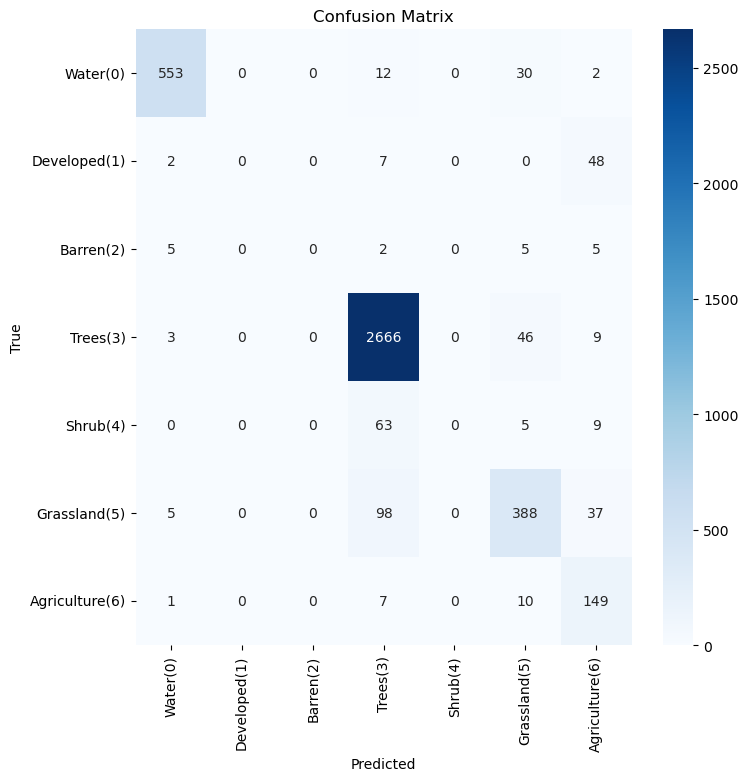

In [36]:
# Create the confusion matrix
cm = confusion_matrix(y_true, y_pred)

# Plot using Seaborn
plt.figure(figsize=(8, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=pixel_label_names, yticklabels=pixel_label_names)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.savefig(figure_name, dpi=600, bbox_inches="tight")
plt.show()

## Test on Training Data (overfitting)

In [37]:
training_loader2 = DataLoader(training_dataset, batch_size=len(training_dataset), shuffle=False)  # a single batch

In [38]:
len(training_loader2), training_loader2.batch_size

(1, 16667)

In [39]:
model.eval()

with torch.no_grad():
    for pixels, labels in training_loader2:
        pixels = pixels.to(device)
        labels = labels.to(device)

        outputs = model(pixels)
        predicted_index = torch.argmax(outputs, dim=1)
        total = pixels.shape[0]
        correct = int((predicted_index == labels).sum())
        
print("Accuracy: %f" % (correct * 100 / total))
print("correct =",correct)
print("total =", total)

Accuracy: 90.214196
correct = 15036
total = 16667


## Save / Load Model to File  
**Deep Learning with Pytorch p214**

In [40]:
file_name='../Pixel_models/' + model_name + '.pt'
file_name

'../Pixel_models/Alpha_BiomeA.pt'

In [41]:
torch.save(model.state_dict(), file_name)

`johns_model.pt` now contains all the parameters of the model - weights and biases. No structure, just the weights.  
So when we deploy the model we need to keep the model class handy, create an instance, and then load the parameters back
into it.

In [44]:
loaded_model = Alpha_FC()           # dont change the model class definition between saving and loading the model
loaded_model.load_state_dict(torch.load('../Pixel_models/Alpha_BiomeA.pt', weights_only=True))

<All keys matched successfully>

In [ ]:
print(loaded_model)

In [ ]:
model=loaded_model